In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_circles

In [3]:
X, y = make_circles(n_samples = 500, noise= 0.3, random_state= 42, factor= 0.2)

In [4]:
X.shape

(500, 2)

In [5]:
y.shape

(500,)

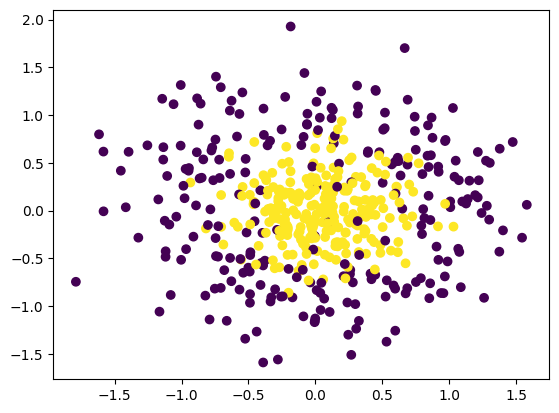

In [6]:
plt.scatter(X[:, 0], X[:, 1], c = y)

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [9]:
# fitting a decision tree

In [10]:
from sklearn.tree import DecisionTreeClassifier

In [11]:
dt = DecisionTreeClassifier(random_state= 42)

In [12]:
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [13]:
y_pred = dt.predict(X_test)

In [14]:
from sklearn.metrics import accuracy_score

In [15]:
accuracy_score(y_test, y_pred)

0.9

In [16]:
# plotting the boundary

In [17]:
x_range = np.linspace(X.min(), X.max(), 500)

In [18]:
xx1, xx2 = np.meshgrid(x_range, x_range)

In [19]:
y_hat = dt.predict(np.c_[xx1.ravel(), xx2.ravel()])
y_hat = y_hat.reshape(xx1.shape)

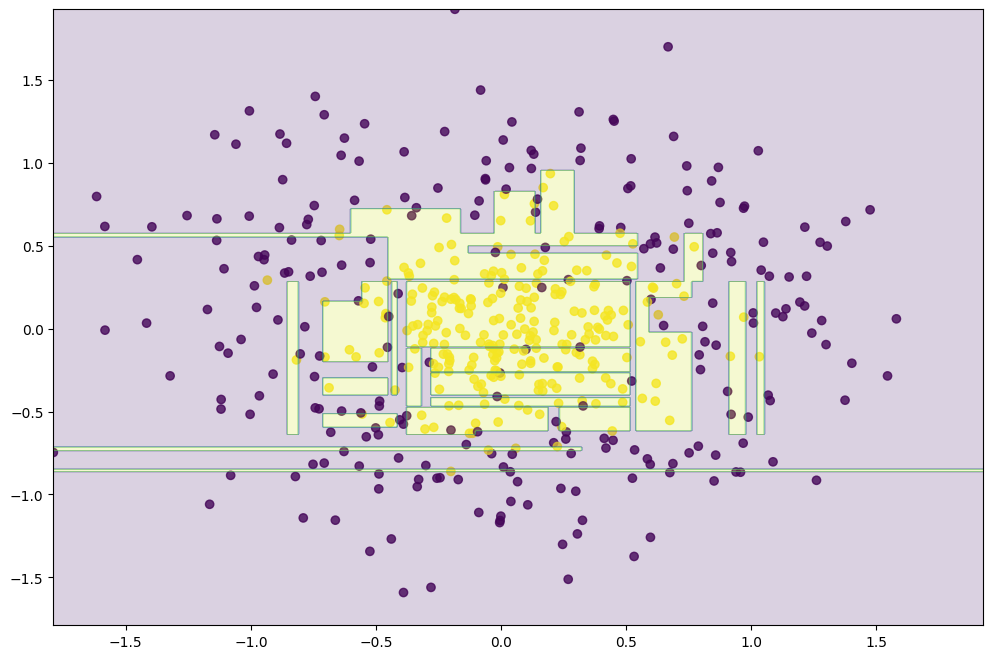

In [23]:
plt.figure(figsize= (12, 8))
plt.scatter(X[:, 0], X[:, 1], c = y, alpha = 0.8)
plt.contourf(xx1, xx2, y_hat, alpha = 0.2)

In [24]:
# now doing for random forest

In [25]:
from sklearn.ensemble import RandomForestClassifier

In [53]:
rf = RandomForestClassifier(random_state= 42, max_samples= 300)

In [54]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [55]:
y_pred = rf.predict(X_test)

In [56]:
accuracy_score(y_test, y_pred)

0.93

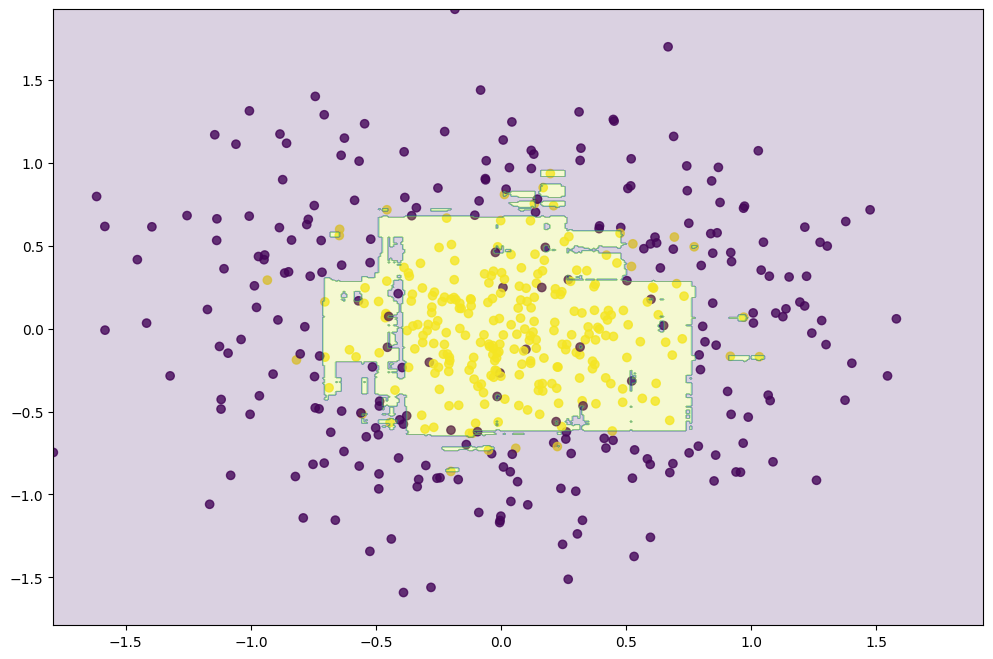

In [57]:
y_hat = rf.predict(np.c_[xx1.ravel(), xx2.ravel()])
y_hat = y_hat.reshape(xx1.shape)
plt.figure(figsize= (12, 8))
plt.scatter(X[:, 0], X[:, 1], c = y, alpha = 0.8)
plt.contourf(xx1, xx2, y_hat, alpha = 0.2)

In [58]:
# now doing for regression

In [59]:
def f(X):
    X = X.ravel()
    return (np.exp(-X**2) + 1.5 * np.exp(-(X-2) ** 2))

def generate(n_samples, noise):
    X = np.random.rand(n_samples) * 10 - 5
    X = np.sort(X).ravel()
    y = f(X)
    y = y + np.random.normal(0, noise, n_samples)
    X = X.reshape((n_samples, 1))
    return X, y

In [60]:
X, y = generate(1000, 0.1)

In [61]:
X_train, y_train = generate(150, 0.1)

(-5.0, 5.0)

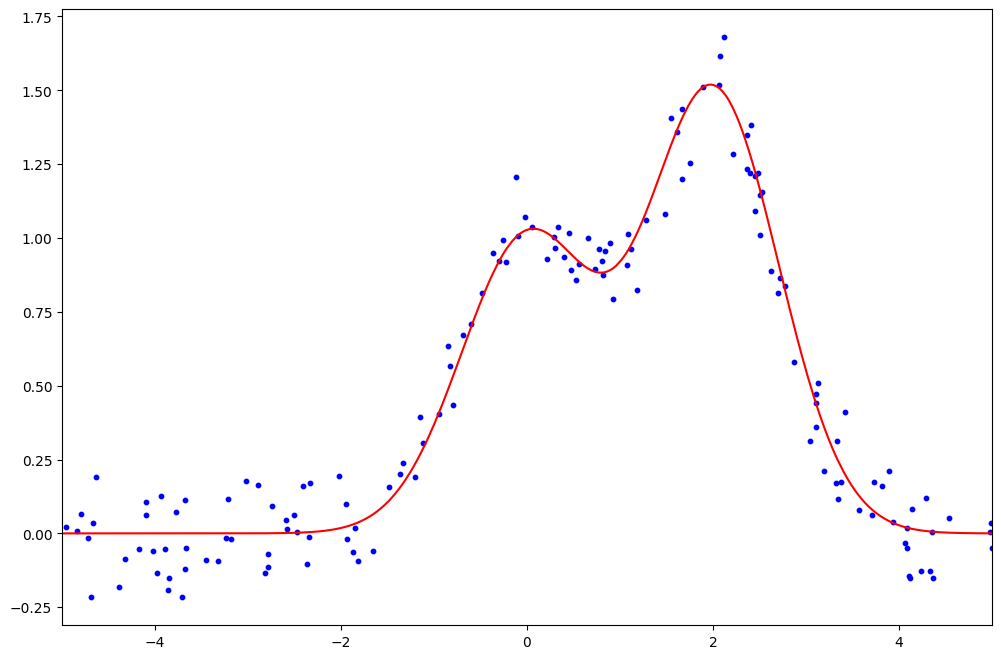

In [65]:
plt.figure(figsize= (12, 8))
plt.plot(X, f(X), color = 'r')
plt.scatter(X_train, y_train, color = 'b', s = 10)
plt.xlim([-5, 5])

In [66]:
from sklearn.tree import DecisionTreeRegressor

In [67]:
dt = DecisionTreeRegressor(random_state= 42)

In [68]:
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [69]:
from sklearn.metrics import r2_score

In [71]:
X_train.shape

(150, 1)

In [75]:
r2_score(y, dt.predict(X))

0.9185786402147186

(-5.0, 5.0)

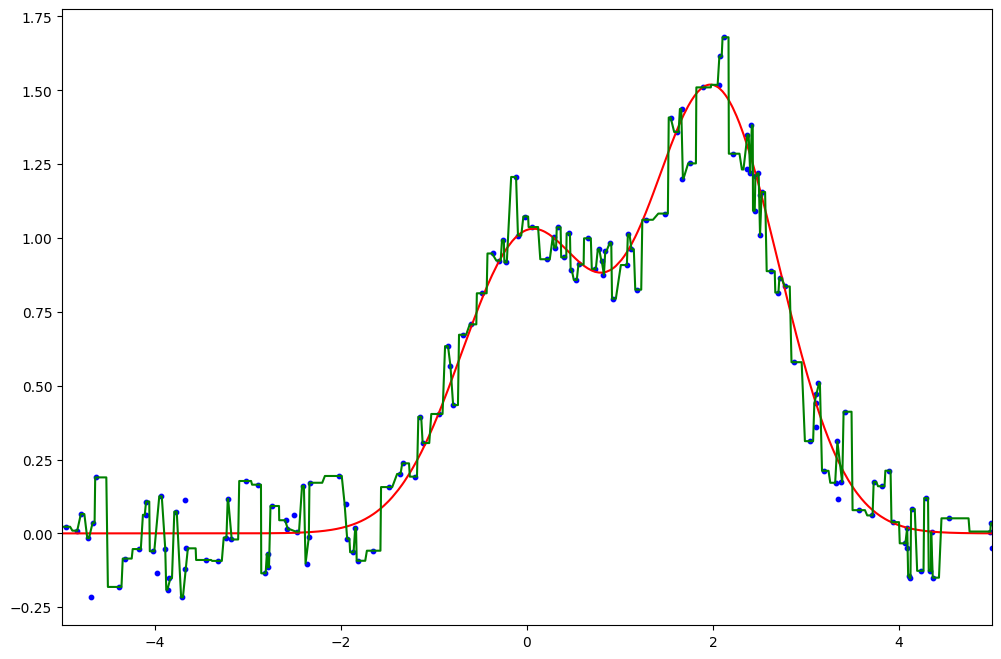

In [77]:
plt.figure(figsize= (12, 8))
plt.plot(X, f(X), color = 'r')
plt.scatter(X_train, y_train, color = 'b', s = 10)
plt.plot(X, dt.predict(X), color = 'g')
plt.xlim([-5, 5])

In [78]:
from sklearn.ensemble import RandomForestRegressor

In [79]:
rf = RandomForestRegressor(max_samples= 100)

In [80]:
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [81]:
r2_score(y, rf.predict(X))

0.946635628650769

(-5.0, 5.0)

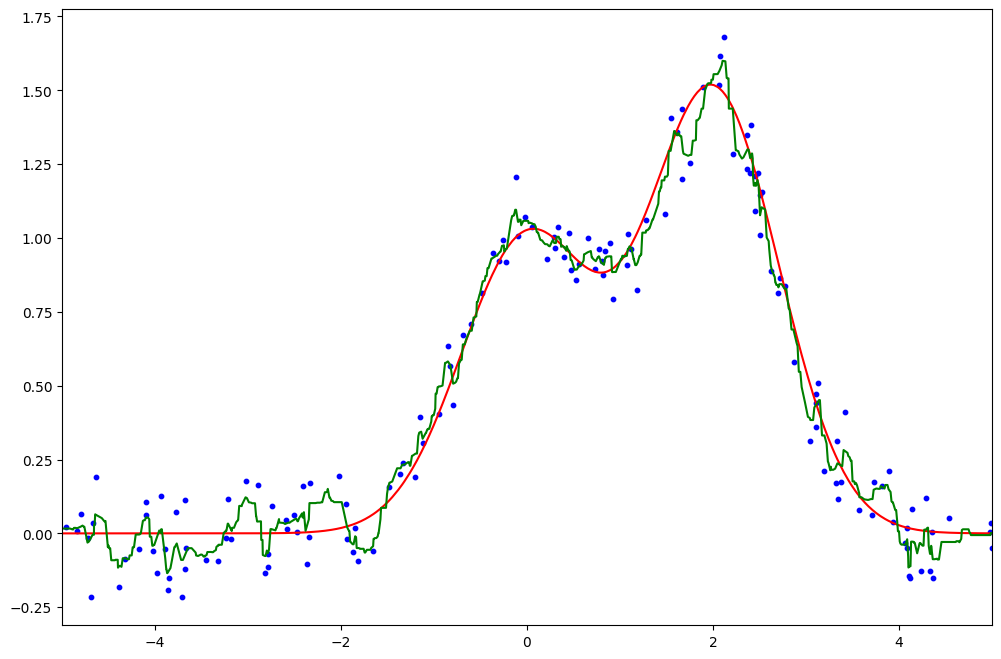

In [82]:
plt.figure(figsize= (12, 8))
plt.plot(X, f(X), color = 'r')
plt.scatter(X_train, y_train, color = 'b', s = 10)
plt.plot(X, rf.predict(X), color = 'g')
plt.xlim([-5, 5])